In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Used_Cars_Homework.csv")

print(df.head(10))
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.describe())

print("Min:", df["price_azn"].min())
print("Max:", df["price_azn"].max())
print("Mean:", df["price_azn"].mean())

   age_years  mileage_km  engine_l  power_hp    brand fuel_type transmission  \
0         11     97064.0       NaN        77  Hyundai    hybrid       manual   
1         10     74340.0       NaN       135      BMW    petrol    automatic   
2          6     69312.0       1.4        95   Toyota    petrol          NaN   
3          8    126280.0       NaN        89      Kia    hybrid    automatic   
4          2     42026.0       1.4        98      BMW    hybrid    automatic   
5         11     89859.0       2.0       120  Hyundai    petrol    automatic   
6          6    124854.0       3.0       196   Toyota    diesel    automatic   
7          4     70952.0       1.8        95      BMW    petrol    automatic   
8         15    248400.0       1.8        90  Hyundai    hybrid    automatic   
9         11    153076.0       2.0       140      BMW    hybrid    automatic   

  accident_history  price_azn  
0               no      16950  
1               no      37335  
2               no     

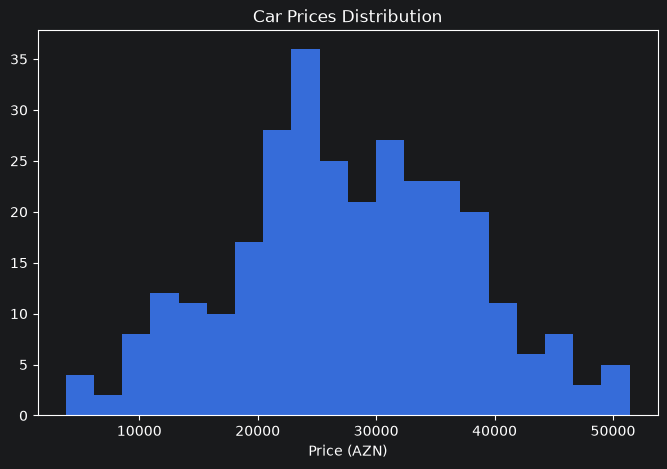

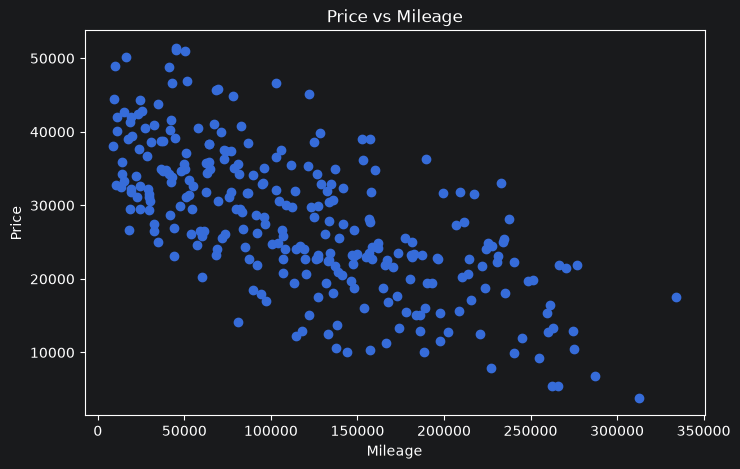

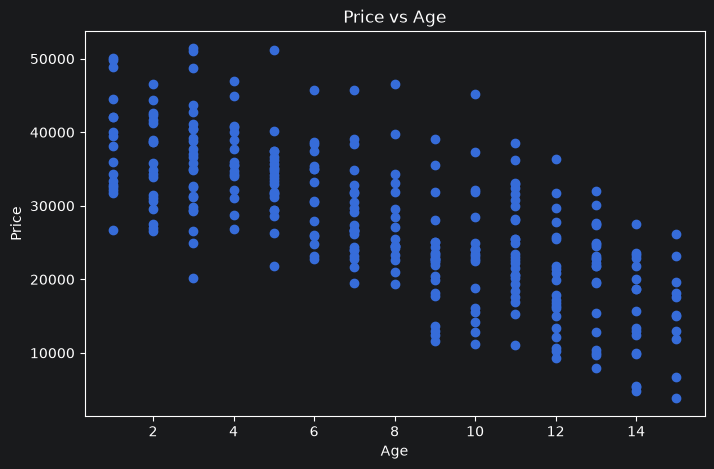

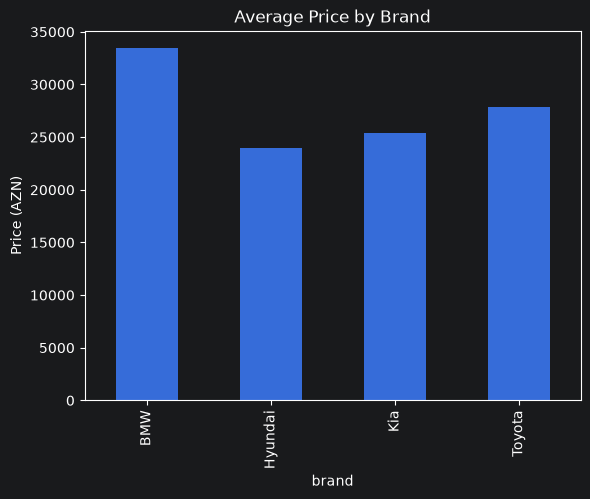

In [2]:
plt.figure(figsize=(8, 5))
plt.hist(df["price_azn"], bins=20)
plt.title("Car Prices Distribution")
plt.xlabel("Price (AZN)")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df["mileage_km"], df["price_azn"])
plt.title("Price vs Mileage")
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df["age_years"], df["price_azn"])
plt.title("Price vs Age")
plt.xlabel("Age")
plt.ylabel("Price")
plt.show()

df.groupby("brand")["price_azn"].mean().plot(kind="bar")
plt.title("Average Price by Brand")
plt.ylabel("Price (AZN)")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df["mileage_per_year"] = df["mileage_km"] / df["age_years"].replace(0, 1)

X = df.drop("price_azn", axis=1)
y = df["price_azn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(pd.factorize(X_train["brand"])[0][:10])
print(pd.get_dummies(X_train["brand"]).head())

print(MinMaxScaler().fit_transform(X_train[["mileage_km"]])[:5])
print(StandardScaler().fit_transform(X_train[["mileage_km"]])[:5])

num_cols = ["age_years", "mileage_km", "engine_l", "power_hp", "mileage_per_year"]
cat_cols = ["brand", "fuel_type", "transmission", "accident_history"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

[0 1 1 0 1 0 1 1 2 0]
       BMW  Hyundai    Kia  Toyota
232   True    False  False   False
59   False    False  False    True
6    False    False  False    True
185   True    False  False   False
173  False    False  False    True
[[0.13514983]
 [0.22392721]
 [0.35681384]
 [       nan]
 [0.01963789]]
[[-0.90397299]
 [-0.51018452]
 [ 0.07925867]
 [        nan]
 [-1.41634751]]


In [4]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", RandomForestRegressor(n_estimators=100, random_state=42))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

results = pd.DataFrame({
    "Real Price": y_test.values,
    "Predicted Price": predictions,
    "Error": abs(y_test.values - predictions)
})

display(results.head(10))

new_cars = pd.DataFrame({
    "age_years": [5, 10, 3],
    "mileage_km": [75000, 180000, 40000],
    "engine_l": [1.6, 2.0, 2.5],
    "power_hp": [110, 140, 170],
    "brand": ["Toyota", "Hyundai", "BMW"],
    "fuel_type": ["petrol", "diesel", "petrol"],
    "transmission": ["automatic", "manual", "automatic"],
    "accident_history": ["no", "yes", "no"]
})

new_cars["mileage_per_year"] = new_cars["mileage_km"] / new_cars["age_years"]

new_cars["Predicted Price"] = model.predict(new_cars)

display(new_cars)

MAE: 2837.0044999999996
MSE: 12903631.104438335
RMSE: 3592.162455184667
R2: 0.8737884139005898


,Real Price,Predicted Price,Error
0,34837,28571.69,6265.31
1,34946,29758.79,5187.21
2,32214,31697.45,516.55
3,36190,35807.32,382.68
4,25000,30332.51,5332.51
5,26522,33340.76,6818.76
6,22711,19959.41,2751.59
7,33061,34944.19,1883.19
8,18479,19758.42,1279.42
9,25003,27229.64,2226.64


,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,mileage_per_year,Predicted Price
0,5,75000,1.6,110,Toyota,petrol,automatic,no,15000.000000,30604.81
1,10,180000,2.0,140,Hyundai,diesel,manual,yes,18000.000000,22909.89
2,3,40000,2.5,170,BMW,petrol,automatic,no,13333.333333,45359.87


Conclusion
The Random Forest algorithm was applied to estimate used car prices. Its performance was measured using MAE, MSE, RMSE, and R². Finally, the model generated price predictions for three different cars.
